
<div align="center">

<img src="https://capsule-render.vercel.app/api?type=waving&color=0:050B18,50:0B3D91,100:123B60&height=190&section=header&text=Luis%20Barahona&fontSize=42&fontColor=FFFFFF&fontAlignY=38&desc=DATA%20ENGINEERING%20%7C%20ARTIFICIAL%20INTELLIGENCE%20%7C%20DEVELOPER&descAlignY=62&descSize=14" width="50%" alt="Luis Barahona MX- Data Engineering and AI">

<img src="https://readme-typing-svg.demolab.com?font=Fira+Code&weight=500&size=17&duration=3500&pause=1200&color=38BDF8&center=true&vCenter=true&width=600&lines=Python+%7C+SQL+%7C+Data+Engineering;Artificial+Intelligence+%7C+Machine+Learning;Data+Science+%7C+Cloud+Computing;Building+Technology+for+the+Future" alt="Technical expertise">

</div>

---
<div align="center">
### Professional Profile

I am a Mexican Data Engineer and a 2026 graduate of Universidad del Caribe, passionate about technology, innovation, and continuous learning.
Beyond technical expertise, I value communication, teamwork, collaboration, and building meaningful connections with others. I believe that every person offers an opportunity to learn something new, and I am always motivated to share knowledge, explore new ideas, and grow both personally and professionally.

---

<div align="center">

<img src="https://skillicons.dev/icons?i=python,mysql,postgres,git,github,react,firebase,linux,docker,vscode&theme=dark" alt="Technical skills">


<strong>Data Engineering ·  Data Analytics · Data science · Artificial Intelligence · Machine Learning · Data Analytics · Developer</strong>

</div>

---
<div align="center">

| Platform | Contact |
|:---|:---|
| Email | [190300395@ucaribe.edu.mx](mailto:190300395@ucaribe.edu.mx) |
| GitHub | [github.com/LuisBarahonaMX](https://github.com/LuisBarahonaMX) |
| LinkedIn | [linkedin.com/in/luis-barahona-mx](https://www.linkedin.com/in/luis-barahona-mx/) |
| Instagram | [@luisbarahonamx](https://www.instagram.com/luisbarahonamx/) |
| X | [@luisbarahonaMX](https://x.com/luisbarahonaMX) |
| Website | [SIKO AI Platform](https://sikoai.web.app/) |
</div>



# 🌦️ Análisis de Series Temporales con SARIMA y Prophet
En esta práctica se analiza el comportamiento climático en Delhi usando modelos de series temporales: **SARIMA** y **Prophet**. Se aplican técnicas de entrenamiento y validación con base en el último año disponible, comparando ambos modelos para las variables más significativas del dataset.

In [ ]:
!pip install --upgrade numpy
!pip install --upgrade pmdarima

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.4/16.4 MB 45.4 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.2.4 which is incompatible.
tensorflow 2.18.0 requires numpy<2.1.0,>=1.26.0, but you have numpy 2.2.4 which is incompatible.


In [ ]:
!pip install "pmdarima<=2.0.3"
!pip install numpy==1.24

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 58.4 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.4
    Uninstalling numpy-2.2.4:
      Successfully uninstalled numpy-2.2.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
blosc2 3.2.1 requires numpy>=1.26, but you have numpy 1.24.0 which is incompatible.
jax 0.5.2 requires numpy>=1.25, but you have numpy 1.24.0 which is incompatible.
albumentations 2.0.5 requires numpy>=1.24.4, but you have numpy 1.24.0 which is incompatible.
chex 0.1.89 requires numpy>=1.24.1, but you have numpy 1.24.0 which is incompatible.
albucore 0.0.23 requires numpy>=1.24.4, but you have numpy 1.24.0 which is incompatible.
pymc 5.21.1 requires numpy>=1.25.0, but you have numpy 1.24.0 which is incompatible.
tensorflow 2.18.0 requires numpy<2.1.0,>=1.26.0, but you have numpy 1.24.0 which

In [ ]:
!pip install pmdarima prophet --quiet
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pmdarima import auto_arima
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet
from sklearn.metrics import mean_squared_error

## 📥 Cargar datasets desde archivos subidos manualmente

In [ ]:
# Subir los archivos desde tu equipo
from google.colab import files
uploaded = files.upload()

TypeError: 'NoneType' object is not subscriptable

In [ ]:
# Cargar archivos CSV
df_train = pd.read_csv('DailyDelhiClimateTrain.csv', parse_dates=['date'])
df_test = pd.read_csv('DailyDelhiClimateTest.csv', parse_dates=['date'])

# Combinar ambos datasets y ordenar por fecha
df = pd.concat([df_train, df_test]).sort_values('date').reset_index(drop=True)
df.set_index('date', inplace=True)
df.head()

,meantemp,humidity,wind_speed,meanpressure
date,,,,
2013-01-01,10.000000,84.500000,0.000000,1015.666667
2013-01-02,7.400000,92.000000,2.980000,1017.800000
2013-01-03,7.166667,87.000000,4.633333,1018.666667
2013-01-04,8.666667,71.333333,1.233333,1017.166667
2013-01-05,6.000000,86.833333,3.700000,1016.500000


## ✂️ Separar conjunto de entrenamiento y validación

In [ ]:
split_date = df.index.max() - pd.DateOffset(years=1)
df_train = df[df.index < split_date]
df_val = df[df.index >= split_date]
df_train.tail(), df_val.head()

(             meantemp   humidity  wind_speed  meanpressure
 date                                                      
 2016-04-19  34.000000  33.600000    4.566667   1005.866667
 2016-04-20  34.062500  25.937500   14.018750   1006.437500
 2016-04-21  34.000000  24.666667   15.750000   1003.400000
 2016-04-22  33.250000  24.250000    8.350000   1001.727273
 2016-04-23  31.916667  21.818182   19.653846   1001.846154,
              meantemp   humidity  wind_speed  meanpressure
 date                                                      
 2016-04-24  31.312500  22.125000   10.187500   1003.062500
 2016-04-25  31.750000  22.812500    6.950000   1005.562500
 2016-04-26  33.437500  25.187500    3.831250   1007.187500
 2016-04-27  33.125000  29.062500    4.981250   1005.687500
 2016-04-28  34.153846  21.769231   11.823077   1004.692308)

## 🔁 Ajuste de modelos SARIMA por variable (usando AIC)

In [ ]:
results_sarima = {}
for col in ['meantemp', 'humidity']:
    print(f"⏳ Ajustando SARIMA para: {col}")
    model_sel = auto_arima(df_train[col], seasonal=True, m=12, trace=True, suppress_warnings=True)
    model = SARIMAX(df_train[col], order=model_sel.order, seasonal_order=model_sel.seasonal_order)
    fitted = model.fit(disp=False)
    forecast = fitted.forecast(steps=len(df_val))
    results_sarima[col] = (forecast, fitted.aic)
    print(f"AIC: {fitted.aic:.2f}")

⏳ Ajustando SARIMA para: meantemp
Performing stepwise search to minimize aic


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11

 ARIMA(2,0,2)(1,0,1)[12] intercept   : AIC=inf, Time=16.39 sec
 ARIMA(0,0,0)(0,0,0)[12] intercept   : AIC=8270.151, Time=0.07 sec


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(1,0,0)(1,0,0)[12] intercept   : AIC=4655.377, Time=5.05 sec


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


... (115 outputs left out)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(2,0,3)(0,0,0)[12]             : AIC=8427.814, Time=0.86 sec

Best model:  ARIMA(2,0,3)(0,0,0)[12] intercept
Total fit time: 85.072 seconds


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


AIC: 8427.81


## 🔮 Ajuste de modelos Prophet por variable

In [ ]:
results_prophet = {}
for col in ['meantemp', 'humidity']:
    print(f"🔮 Ajustando Prophet para {col}...")
    df_p = df[[col]].reset_index().rename(columns={"date": "ds", col: "y"})
    df_train_p = df_p[df_p['ds'] < split_date]
    df_val_p = df_p[df_p['ds'] >= split_date]
    model = Prophet()
    model.fit(df_train_p)
    future = model.make_future_dataframe(periods=len(df_val_p))
    forecast = model.predict(future)
    forecast_val = forecast[['ds', 'yhat']].tail(len(df_val_p)).reset_index(drop=True)
    forecast_val['y'] = df_val_p['y'].reset_index(drop=True)
    results_prophet[col] = forecast_val

🔮 Ajustando Prophet para meantemp...


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
DEBUG:cmdstanpy:input tempfile: /tmp/tmp5um16edg/i0q36cd4.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp5um16edg/7w8y7xg9.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=83785', 'data', 'file=/tmp/tmp5um16edg/i0q36cd4.json', 'init=/tmp/tmp5um16edg/7w8y7xg9.json', 'output', 'file=/tmp/tmp5um16edg/prophet_modelfty71etj/prophet_model-20250405210513.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
21:05:13 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
21:05:13 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
DEBUG:cmdstanpy:input tempfile: /tmp/tmp5u

🔮 Ajustando Prophet para humidity...


21:05:14 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


## 📊 Comparación de Modelos SARIMA vs Prophet con RMSE y Gráfica


📈 Variable: meantemp
SARIMA → AIC: 4589.91, RMSE: 7.56
Prophet → RMSE: 4.76


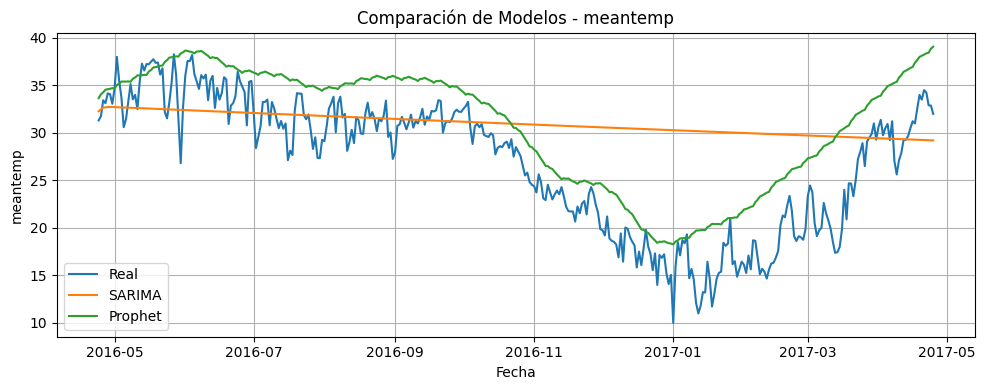


📈 Variable: humidity
SARIMA → AIC: 8427.81, RMSE: 39.84
Prophet → RMSE: 12.40


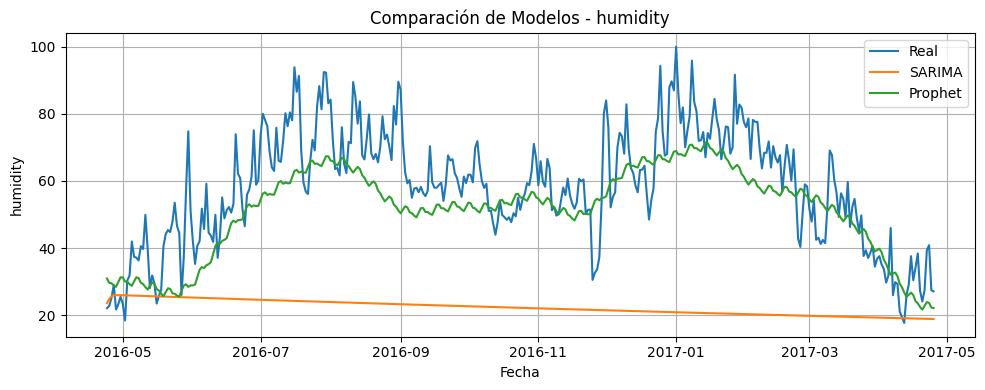

In [ ]:
for col in ['meantemp', 'humidity']:
    forecast_sarima, aic = results_sarima[col]
    prophet_df = results_prophet[col]
    y_true = prophet_df['y'].values
    yhat_prophet = prophet_df['yhat'].values
    yhat_sarima = forecast_sarima[-len(y_true):].values
    rmse_sarima = mean_squared_error(y_true, yhat_sarima) ** 0.5
    rmse_prophet = mean_squared_error(y_true, yhat_prophet) ** 0.5
    print(f"\n📈 Variable: {col}")
    print(f"SARIMA → AIC: {aic:.2f}, RMSE: {rmse_sarima:.2f}")
    print(f"Prophet → RMSE: {rmse_prophet:.2f}")
    # Gráfico comparativo
    plt.figure(figsize=(10, 4))
    plt.plot(prophet_df['ds'], y_true, label='Real')
    plt.plot(prophet_df['ds'], yhat_sarima, label='SARIMA')
    plt.plot(prophet_df['ds'], yhat_prophet, label='Prophet')
    plt.title(f'Comparación de Modelos - {col}')
    plt.xlabel('Fecha')
    plt.ylabel(col)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()